In [30]:
import pandas as pd

In [31]:
df = pd.read_csv("case_summary.csv",index_col=0)
df.drop(columns=["case number"], inplace=True)
df.shape

(110, 73)

In [27]:
df

,P/E mean,P/E standard deviation,P/E min,P/E max,P/B mean,P/B standard deviation,P/B min,P/B max,P/S mean,P/S standard deviation,...,VEC max,PLF mean,PLF standard deviation,PLF min,PLF max,IQS mean,IQS standard deviation,IQS min,IQS max,Time Range
0,41.912397,44.504757,0.000000,189.664660,12.084984,13.422656,0.684142,51.928970,7.387663,7.344796,...,63.387253,0.008948,0.007801,0.000000,0.026433,0.005007,0.009567,0.000000e+00,0.043003,60
1,24.437059,8.909828,0.000000,45.122520,2.567630,22.788641,0.000000,208.927400,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,60
2,51.776397,93.994490,11.804184,657.833400,16.262456,37.935293,-61.937490,234.477620,9.399454,17.027223,...,219.456159,0.006787,0.009248,0.000000,0.047101,1.052831,7.424089,0.000000e+00,52.499137,8
3,21.983709,19.410395,0.000000,57.712753,3.715646,24.762996,-51.852524,51.870970,5.606651,8.478630,...,20.380264,0.004467,0.004919,0.000000,0.014026,0.002320,0.002868,0.000000e+00,0.008519,156
4,20.812813,10.303295,9.922092,42.296295,0.598383,23.257026,-62.335957,26.290714,3.840208,2.410483,...,27.075351,0.010367,0.009075,0.000000,0.026381,0.008079,0.008078,0.000000e+00,0.020488,156
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,50.570402,51.892643,0.000000,241.243910,0.792947,15.321000,-41.769430,28.867039,8.574027,2.498760,...,36.864885,0.002698,0.004781,0.000000,0.020848,0.000830,0.000848,0.000000e+00,0.003356,180
106,21.600822,4.041695,12.843945,28.927633,2.092668,0.532926,1.057075,3.083731,3.203772,1.164286,...,8.893835,0.002117,0.000508,0.001042,0.002672,0.003321,0.001479,1.138584e-03,0.006423,180
107,161.684636,581.659059,0.000000,2491.666700,4.217299,4.376622,0.976688,18.913473,2.889103,1.789814,...,832.007946,0.001790,0.002477,0.000000,0.009177,0.001807,0.002062,0.000000e+00,0.008064,180
108,127.078174,187.737392,16.527014,651.500000,21.207299,22.242434,4.970821,68.012180,25.215565,33.872288,...,217.345026,0.005546,0.007169,0.000152,0.018798,0.001160,0.001924,3.759656e-07,0.006274,180


降维后shape: (110, 10)
实际保留的维数: 14
各主成分解释的方差比: [0.33069977 0.15457765 0.08867772 0.07002685 0.06224008 0.04857415
 0.04486549 0.03625352 0.03179632 0.02423112 0.02209336 0.01627823
 0.01401713 0.0127062 ]


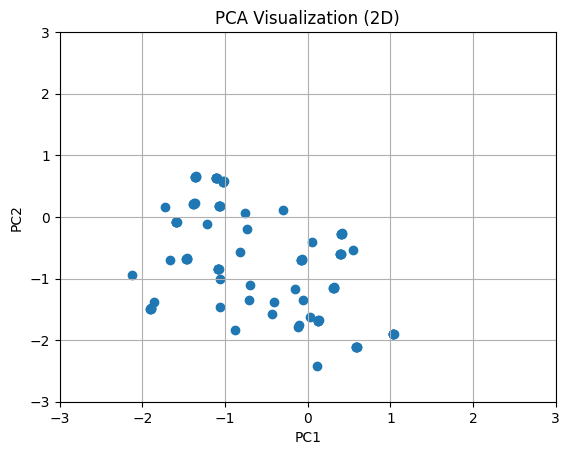

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 假设你的 DataFrame 是 df，shape 为 (110, 75)
# 可以是你加载好的财务数据、图像数据、传感器数据等
X = df.values  # 将DataFrame转换为numpy数组

# 标准化
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

pca = PCA(n_components=10)
X_pca = pca.fit_transform(X_std)

print("降维后shape:", X_pca.shape)

pca = PCA(n_components=0.95)  # 自动确定维数，保留95%的信息
X_pca = pca.fit_transform(X_std)

print("实际保留的维数:", X_pca.shape[1])
print("各主成分解释的方差比:", pca.explained_variance_ratio_)

import matplotlib.pyplot as plt

pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_std)

plt.scatter(X_2d[:, 0], X_2d[:, 1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Visualization (2D)")
plt.grid(True)
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.show()


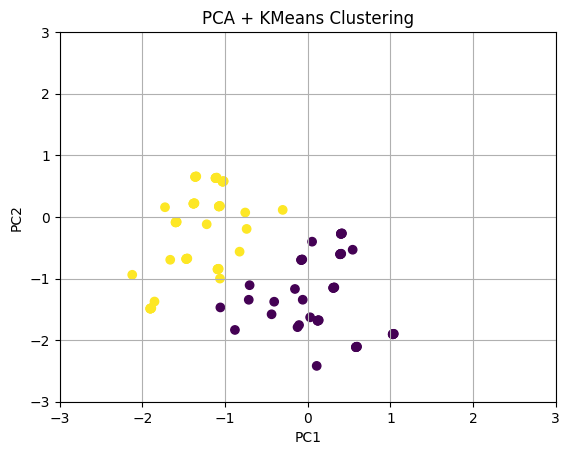

In [38]:
from sklearn.cluster import KMeans
pca_2d = pca_2d.fit_transform(X_std)
kmeans = KMeans(n_clusters=4).fit(pca_2d)
labels = kmeans.labels_

# 可视化聚类结果
plt.scatter(pca_2d[:, 0], pca_2d[:, 1], c=labels, cmap='viridis')
plt.title("PCA + KMeans Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.show()


In [29]:
from sklearn.decomposition import LatentDirichletAllocation
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

# 假设你已经有这个 DataFrame
# df.shape == (110, 75)

# 初始化LDA模型
lda_model = LatentDirichletAllocation(n_components=5,  # 主题数，可调
                                      random_state=42,
                                      learning_method='batch')

# 拟合模型
lda_result = lda_model.fit_transform(df_scaled)

# 查看每个样本的主题分布
lda_result_df = pd.DataFrame(lda_result)
print(lda_result_df.head())


          0         1         2         3         4
0  0.009937  0.009749  0.960592  0.009921  0.009801
1  0.012315  0.012308  0.950717  0.012352  0.012307
2  0.007632  0.007472  0.969681  0.007576  0.007638
3  0.011393  0.011222  0.954728  0.011386  0.011271
4  0.010199  0.010003  0.959641  0.010121  0.010036


In [4]:
import pandas as pd
df = pd.read_csv("instance_summary.csv")
dt = pd.read_csv("instance_summary2020.csv")
result = pd.concat([df,dt],ignore_index=True)
result.drop(columns=["Unnamed: 0"],inplace=True)
result.to_csv("instance_summary_all.csv")